In [1]:
from dataclasses import dataclass

import cvxpy as cp
import numpy as np
import pandas as pd

### 1.1. Градиент и гессиан

Рассматриваем функцию

$$f(x)=\frac12\|Ax-b\|_2^2+\frac\alpha2\|x-a\|_2^2,
\qquad x\in\mathbb R^n.$$

Матрица $A\in\mathbb R^{m\times n}$, векторы $a\in\mathbb R^n$,
$b\in\mathbb R^m$ и $\alpha\ge0$.

Раскроем квадраты:

$$f(x)=\frac12x^\top A^\top Ax-b^\top Ax+\frac12b^\top b
+\frac\alpha2x^\top x-\alpha a^\top x+\frac\alpha2a^\top a.$$

Найдем градиент каждого слагаемого отдельно. Сначала обозначим
$B=A^\top A$. Матрица $B$ симметрична, так как
$(A^\top A)^\top=A^\top A$.

Запишем квадратичную форму как сумму

$$\frac12x^\top Bx=\frac12\sum_{i=1}^n\sum_{j=1}^n B_{ij}x_i x_j.$$

По правилу производной произведения

$$\frac{\partial}{\partial x_k}\left(\frac12x^\top Bx\right)
=\frac12\sum_{j=1}^n B_{kj}x_j
+\frac12\sum_{i=1}^n B_{ik}x_i.$$

В векторной записи получаем

$$\nabla\left(\frac12x^\top Bx\right)
=\frac12(B+B^\top)x=Bx=A^\top Ax.$$

Линейное слагаемое перепишем как
$-b^\top Ax=-(A^\top b)^\top x$.
Дифференцируем

$$\nabla(-b^\top Ax)=-A^\top b.$$

Оставшиеся слагаемые дифференцируем аналогично:

$$\nabla\left(\frac\alpha2x^\top x\right)=\alpha x,
\qquad \nabla(-\alpha a^\top x)=-\alpha a.$$

Величины $b^\top b/2$ и $\alpha a^\top a/2$ константны,
поэтому их градиенты равны нулю. Складывая результаты, получаем

$$\nabla f(x)=A^\top Ax-A^\top b+\alpha x-\alpha a
=A^\top(Ax-b)+\alpha(x-a).$$

Гессиан имеет вид

$$\nabla^2 f(x)=A^\top A+\alpha I_n.$$

Обозначим

$$H=A^\top A+\alpha I_n,\qquad q=A^\top b+\alpha a.$$

Тогда $\nabla f(x)=Hx-q$.

### 1.2. Выпуклость

Функция выпукла, если
для любых $x,y$ и $t\in[0,1]$

$$f((1-t)x+ty)\le(1-t)f(x)+tf(y).$$

Для дифференцируемой функции на выпуклой области это равносильно условию

$$f(y)\ge f(x)+\langle\nabla f(x),y-x\rangle.$$

То есть график функции лежит не ниже ее касательной линейной функции.
Область $\mathbb R^n$ выпукла.

Пусть $d=y-x$. Поскольку функция квадратичная, ее разложение Тейлора
равно:

$$f(y)=f(x)+\langle\nabla f(x),d\rangle+\frac12d^\top Hd.$$

При этом

$$d^\top Hd=\|Ad\|_2^2+\alpha\|d\|_2^2\ge0.$$

Отсюда следует

$$f(y)\ge f(x)+\langle\nabla f(x),d\rangle.$$

Следовательно, функция выпукла
при всех допустимых значениях

### 1.3. Липшицевость градиента

Используем определение

$$\|\nabla f(x)-\nabla f(y)\|_2\le L\|x-y\|_2$$

Для нашей функции

$$\nabla f(x)-\nabla f(y)=H(x-y),$$
$$\|H(x-y)\|_2\le\|H\|_2\|x-y\|_2.$$

Спектральная норма матрицы равна

$$\|B\|_2=\max_{\|v\|_2=1}\|Bv\|_2.$$

У симметричной положительно полуопределенной матрицы она равна
максимальному собственному значению. Поэтому точная константа равна

$$L=\lambda_{\max}(H)
=\lambda_{\max}(A^\top A)+\alpha
=\sigma_{\max}(A)^2+\alpha.$$

где $\sigma_{\max}(A)$ - максимальное сингулярное число $A$.

### 1.4. Сильная выпуклость

Функция $\mu$-сильно выпукла при $\mu>0$, если

$$f(y)\ge f(x)+\langle\nabla f(x),y-x\rangle
+\frac\mu2\|y-x\|_2^2\quad\text{для всех }x,y.$$

По разложению квадратичной функции в ряд Тейлора это то же самое, что для всех $d=y-x$ выполняется

$$d^\top Hd\ge\mu\|d\|_2^2.$$

Это означает, что $H-\mu I_n$ положительно полуопределена и то же самое, что
$\lambda_{\min}(H)\ge\mu$.

Для любой симметричной матрицы $H$ квадратичная форма оценивается
через крайние собственные значения. Разложим
$d=\sum_i c_i u_i$ по ортонормированным собственным векторам $H$.
Тогда

$$d^\top Hd=\sum_i\lambda_i c_i^2,\qquad
\|d\|_2^2=\sum_i c_i^2.$$

Поскольку $\lambda_{\min}(H)\le\lambda_i\le\lambda_{\max}(H)$, получаем

$$\lambda_{\min}(H)\|d\|_2^2
\le d^\top Hd\le\lambda_{\max}(H)\|d\|_2^2.$$

Максимальная константа сильной выпуклости равна

$$\mu=\lambda_{\min}(H)\qquad
\text{при }\lambda_{\min}(H)>0.$$

Теперь найдем $\mu$. Так как $ H=A^\top A+\alpha I_n $ имеем

$$\mu=\lambda_{\min}(A^\top A)+\alpha.$$

Матрица $A^\top A$ положительно полуопределена, поскольку для любого $d$

$$d^\top A^\top Ad=\|Ad\|_2^2\ge0.$$

Поэтому $\lambda_{\min}(A^\top A)\ge0$ и

$$ \mu\ge\alpha.$$

При $\alpha>0$ имеем $\mu\ge\alpha>0$, поэтому функция сильно выпукла.

При $\alpha=0$ сильная выпуклость это то же самое, что и $\operatorname{rank}A=n$.
Так как $A^\top A$ положительно, когда $\ker A=\{0\}$, то
при $\operatorname{rank}A<n$ получаем $\mu=0$, то есть сильной выпуклости нет.


### 1.5. Условия оптимальности

Так как ограничений на $x$ нет, необходимое условие минимума имеет вид

$$\nabla f(x^*)=0.$$


В нашем случае функция выпукла, поэтому условие достаточно. Следовательно, $x^*$ - глобальный минимум. Получаем систему

$$A^\top(Ax^*-b)+\alpha(x^*-a)=0$$

Ее можно переписать в виде

$$(A^\top A+\alpha I_n)x^*=A^\top b+\alpha a.$$

Заменив обозначения, получаем

$$Hx^*=q$$

При $\mu>0$ матрица $H$ положительно определена и обратима, поэтому
минимум существует и единственный: $x^*=H^{-1}q$.

При $\alpha=0$ условие оптимальности имеет вид

$$A^\top A x^*=A^\top b.$$

Минимум существует.
При $\operatorname{rank}A<n$ он неединственный

### 2.1. Генерация данных

Для каждого $n\in\{10,20,\ldots,100\}$ выбираем $m=n/2$
и создаем 100 примеров: по 50 при $\alpha=0$ и $\alpha=1$.
Поскольку $m<n$, имеем $\mu=\alpha$. При $\alpha=0$ минимум
неединственный, при $\alpha=1$ - единственный.

In [2]:
SEED = 42
DIMENSIONS = tuple(range(10, 101, 10))
EXAMPLES_PER_GROUP = 50
EPS = 1e-10

### 2.2. Поиск минимума

Используем CVXPY с солвером OSQP. Создаем переменную $x\in\mathbb R^n$
и минимизируем исходную функцию:

$$\min_x\;\frac12\|Ax-b\|_2^2+\frac\alpha2\|x-a\|_2^2.$$

Для солвера задаем допуски $10^{-12}$, чтобы затем проверить
условие оптимальности с допуском $10^{-10}$.
При $\mu=0$ минимизатор неединственный, CVXPY возвращает один из них.

In [3]:
@dataclass
class Problem:
    A: np.ndarray
    a: np.ndarray
    b: np.ndarray
    alpha: float
    group: str


def objective(problem, x):
    residual = problem.A @ x - problem.b
    displacement = x - problem.a
    return float(
        0.5 * (residual @ residual)
        + 0.5 * problem.alpha * (displacement @ displacement)
    )


def gradient(problem, x):
    return problem.A.T @ (problem.A @ x - problem.b) + problem.alpha * (x - problem.a)


def spectral_constants(problem):
    m, n = problem.A.shape
    singular_values = np.linalg.svd(problem.A, compute_uv=False)
    L = float(singular_values[0] ** 2 + problem.alpha)
    lambda_min = 0.0 if m < n else float(singular_values[-1] ** 2)
    mu = lambda_min + problem.alpha
    return L, mu


def solve_problem(problem):
    x = cp.Variable(problem.A.shape[1])
    cost = 0.5 * cp.sum_squares(
        problem.A @ x - problem.b
    ) + 0.5 * problem.alpha * cp.sum_squares(x - problem.a)
    task = cp.Problem(cp.Minimize(cost))
    task.solve(solver=cp.OSQP, eps_abs=1e-12, eps_rel=1e-12)
    return x.value

### 2.3. Проверка условия оптимальности

В точке минимума градиент должен быть равен нулю:

$$\nabla f(x^*)=A^\top(Ax^*-b)+\alpha(x^*-a)=0.$$

In [4]:
rng = np.random.default_rng(SEED)
problems, solutions, rows = [], [], []

for n in DIMENSIONS:
    m = n // 2
    for alpha in (0.0, 1.0):
        group = f"alpha={alpha:g}"
        for sample in range(EXAMPLES_PER_GROUP):
            problem = Problem(
                A=rng.standard_normal((m, n)) / np.sqrt(m),
                a=rng.standard_normal(n),
                b=rng.standard_normal(m),
                alpha=alpha,
                group=group,
            )
            L, mu = spectral_constants(problem)
            x_star = solve_problem(problem)
            grad_norm = np.linalg.norm(gradient(problem, x_star))

            problems.append(problem)
            solutions.append(x_star)
            rows.append(
                {
                    "n": n,
                    "m": m,
                    "group": group,
                    "sample": sample + 1,
                    "alpha": alpha,
                    "L": L,
                    "mu": mu,
                    "kappa": L / mu if mu > 0 else np.nan,
                    "f_star": objective(problem, x_star),
                    "fit_residual": np.linalg.norm(problem.A @ x_star - problem.b),
                    "grad_norm": grad_norm,
                    "is_optimal": grad_norm <= EPS,
                }
            )

results = pd.DataFrame(rows)

print(f"Решено задач: {len(results)}")
print(f"Условие оптимальности выполнено: {results['is_optimal'].sum()}")

Решено задач: 1000
Условие оптимальности выполнено: 1000


Для каждой размерности выведем число задач, число пройденных проверок,
максимальную норму градиента и крайние значения $L$ и $\mu$.

In [5]:
summary_by_n = (
    results.groupby("n")
    .agg(
        examples=("n", "size"),
        is_optimal=("is_optimal", "sum"),
        max_grad_norm=("grad_norm", "max"),
        min_L=("L", "min"),
        max_L=("L", "max"),
        min_mu=("mu", "min"),
        max_mu=("mu", "max"),
    )
    .rename(
        columns={
            "examples": "Число задач",
            "is_optimal": "Проверок пройдено",
            "max_grad_norm": "Макс. норма градиента",
            "min_L": "Мин. L",
            "max_L": "Макс. L",
            "min_mu": "Мин. mu",
            "max_mu": "Макс. mu",
        }
    )
)

summary_by_n

,Число задач,Проверок пройдено,Макс. норма градиента,Мин. L,Макс. L,Мин. mu,Макс. mu
n,,,,,,,
10,100,100,2.517126e-15,2.401816,10.055468,0.0,1.0
20,100,100,2.196051e-15,3.463115,8.392240,0.0,1.0
30,100,100,2.906920e-15,4.057366,7.620945,0.0,1.0
40,100,100,5.692906e-15,4.411512,7.674370,0.0,1.0
50,100,100,4.602984e-15,4.497659,7.117780,0.0,1.0
60,100,100,3.831374e-15,4.880294,7.452257,0.0,1.0
70,100,100,5.049246e-15,4.866588,7.214433,0.0,1.0
80,100,100,9.232916e-15,4.947335,7.136008,0.0,1.0
90,100,100,5.741195e-15,4.951635,7.146821,0.0,1.0


Во всех размерностях получено по 100 решений, все они оптимальны

In [6]:
summary_by_group = (
    results.groupby("group", sort=False)
    .agg(
        examples=("n", "size"),
        min_mu=("mu", "min"),
        max_mu=("mu", "max"),
        max_kappa=("kappa", "max"),
        mean_f_star=("f_star", "mean"),
        max_fit_residual=("fit_residual", "max"),
        max_grad_norm=("grad_norm", "max"),
    )
    .rename(
        columns={
            "examples": "Число задач",
            "min_mu": "Мин. mu",
            "max_mu": "Макс. mu",
            "max_kappa": "Макс. κ",
            "mean_f_star": "Среднее f*",
            "max_fit_residual": "Макс. остаток Ax-b",
            "max_grad_norm": "Макс. норма градиента",
        }
    )
)
summary_by_group.index.name = "Группа"

summary_by_group

,Число задач,Мин. mu,Макс. mu,Макс. κ,Среднее f*,Макс. остаток Ax-b,Макс. норма градиента
Группа,,,,,,,
alpha=0,500,0.0,0.0,NaN,1.841837e-30,5.857331e-15,9.232916e-15
alpha=1,500,1.0,1.0,10.055468,1.407860e+01,5.745174e+00,6.225974e-15


При $\alpha=0$ имеем $\mu=0$, а минимальное значение функции близко к нулю.
Это согласуется с тем, что сгенерированные матрицы имеют полный строчный
ранг и система $Ax=b$ разрешима.

При $\alpha=1$ получаем $\mu=1$ и единственный минимум.

При $\alpha>0$ минимизируем ошибку $\|Ax-b\|_2^2$, а также отклонение
$\|x-a\|_2^2$, поэтому в точке минимума равенство $Ax^*=b$
не обязательно выполняется.

Посмотрим на три примера с наибольшей нормой градиента.

In [7]:
worst_examples = results.nlargest(3, "grad_norm")[
    [
        "n",
        "m",
        "alpha",
        "sample",
        "L",
        "mu",
        "f_star",
        "fit_residual",
        "grad_norm",
    ]
].rename(
    columns={
        "sample": "Пример в группе",
        "f_star": "f*",
        "fit_residual": "Норма Ax-b",
        "grad_norm": "Норма градиента",
    }
)

worst_examples

,n,m,alpha,Пример в группе,L,mu,f*,Норма Ax-b,Норма градиента
724,80,40,0.0,25,5.533561,0.0,1.715416e-29,5.857331e-15,9.232916e-15
748,80,40,0.0,49,5.339924,0.0,1.602212e-29,5.660764e-15,9.183307e-15
990,100,50,1.0,41,6.663332,1.0,2.835281e+01,5.028014e+00,6.225974e-15


In [8]:
print(f"Максимальная норма градиента: {results['grad_norm'].max():.3e}")
print(f"Допуск: {EPS:.0e}")
print(f"Задач c единственным минимумом: {results['mu'].gt(0).sum()}")
print(f"Задач c неединственным минимумом: {results['mu'].eq(0).sum()}")

Максимальная норма градиента: 9.233e-15
Допуск: 1e-10
Задач с единственным минимумом: 500
Задач с неединственным минимумом: 500


Условие оптимальности выполнено во всех 1000 задачах. Максимальная норма
градиента равна примерно $9.2\cdot10^{-15}$,
что меньше выбранного допуска $10^{-10}$.
В 500 задачах минимум единственный, а в других 500 нет.

### 3. Общие начальные точки и критерий остановки

Для каждого из 1000 примеров сгенерируем 100 начальных точек из стандартного нормального распределения. Используем отдельный генератор с фиксированным seed.

Для задачи `problems[i]` массив `initial_points[i]` имеет размер $(100, n)$. Строка `initial_points[i][j]` задает старт с номером $j$, где $j$ меняется от 0 до 99. Эталонное решение хранится в `solutions[i]`, а значения $f^*$, $L$ и $\mu$ в строке `results.loc[i]`.

Для проверки точности будем вызывать `reached_accuracy`, передавая в неё текущее значение функции и минимальное значение из раздела 2. Если $f(x_k)-f^*\le 0{,}01$, метод останавливается.

In [9]:
STARTS_PER_PROBLEM = 100
start_rng = np.random.default_rng(SEED + 1)
initial_points = [
    start_rng.standard_normal((STARTS_PER_PROBLEM, problem.A.shape[1]))
    for problem in problems
]

print(f"Число задач: {len(initial_points)}")
print(f"Всего начальных точек: {sum(len(points) for points in initial_points)}")


def reached_accuracy(value, f_star, eps=0.01):
    return value - f_star <= eps

Число задач: 1000
Всего начальных точек: 100000


### 3a. Метод тяжелого шарика

Положим $x_{-1}=x_0$. На каждой итерации используем градиент в текущей точке и смещение с предыдущего шага:

$$x_{k+1}=x_k-h\nabla f(x_k)+\beta(x_k-x_{k-1}).$$

При $\mu>0$ возьмем параметры Поляка для квадратичной функции:

$$h=\frac{4}{(\sqrt L+\sqrt\mu)^2},\qquad
\beta=\left(\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}\right)^2.$$

Остановимся, как только $f(x_k)-f^*\le\varepsilon$, где $\varepsilon=0.01$. Значение $f^*$ берем из решения CVXPY.

In [10]:
from time import perf_counter

import matplotlib.pyplot as plt

accuracy = 0.01


def polyak_parameters(L, mu):
    if mu <= 0:
        raise ValueError("Для параметров Поляка требуется положительное mu.")
    root_sum = np.sqrt(L) + np.sqrt(mu)
    step = 4 / root_sum**2
    beta = ((np.sqrt(L) - np.sqrt(mu)) / root_sum)**2
    return step, beta

Начнем со случая $\mu>0$. Вычислим $h$ и $\beta$ один раз и на каждой итерации прибавим к градиентному шагу долю предыдущего перемещения. По умолчанию используется постоянный шаг.

In [11]:
@dataclass
class HeavyBallResult:
    x: np.ndarray
    iterations: int
    elapsed: float
    converged: bool
    trajectory: list
    errors: list
    local_L: list
    checks: list
    total_checks: int = 0
    trial_L_sum: float = 0.0
    total_rounds: int = 0
    accepted_L_sum: float = 0.0


def run_heavy_ball(problem, x0, f_star, L, mu, eps=0.01, keep_history=False,
                   max_iter=10000, *, parameters=polyak_parameters, choose_step=None):
    start = perf_counter()
    x = np.array(x0, dtype=float, copy=True)
    previous = x
    value = objective(problem, x)
    converged = reached_accuracy(value, f_star, eps)
    iterations = 0
    trajectory = [x] if keep_history else []
    errors = [value - f_star] if keep_history else []
    local_L, checks = [], []
    M = L
    total_checks = 0
    total_rounds = 0
    accepted_L_sum = 0.0
    trial_L_sum = 0.0

    if not converged:
        step, beta = parameters(L, mu)

    while not converged and iterations < max_iter:
        grad = gradient(problem, x)
        displacement = x - previous
        if choose_step is not None:
            candidate, value, M, count, step_L_sum, rounds = choose_step(
                problem, x, value, grad, displacement, M, L, mu, parameters
            )
            total_rounds += rounds
            accepted_L_sum += M
            total_checks += count
            trial_L_sum += step_L_sum
            if keep_history:
                local_L.append(M)
                checks.append(count)
        else:
            candidate = x - step * grad + beta * displacement
            value = objective(problem, candidate)

        previous, x = x, candidate
        iterations += 1
        converged = reached_accuracy(value, f_star, eps)
        if keep_history:
            trajectory.append(x)
            errors.append(value - f_star)

    return HeavyBallResult(
        x, iterations, perf_counter() - start, converged,
        trajectory, errors, local_L, checks, total_checks, trial_L_sum,
        total_rounds, accepted_L_sum
    )

### 4a. Траектория метода при $n=2$

Возьмем $A=(3,1)$, $b=1$, $a=(0,0)$ и $\alpha=1$. Запустим метод с постоянным шагом из точки $(-2,2)$. Линии уровня показывают значения целевой функции, маркеры на траекториях соответствуют отдельным итерациям.

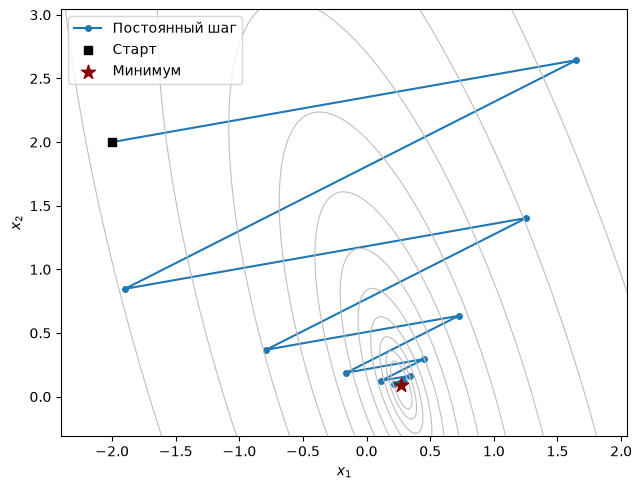

In [12]:
plane_problem = Problem(
    A=np.array([[3.0, 1.0]]), a=np.zeros(2), b=np.ones(1),
    alpha=1.0, group="alpha=1"
)
plane_start = np.array([-2.0, 2.0])
plane_minimum = solve_problem(plane_problem)
plane_value = objective(plane_problem, plane_minimum)
plane_L, plane_mu = spectral_constants(plane_problem)

def plot_trajectories(paths):
    fig, ax = plt.subplots(figsize=(7, 5))
    for label, path in paths.items():
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=4, label=label)

    points = np.vstack([plane_minimum, *paths.values()])
    lower = points.min(axis=0) - 0.4
    upper = points.max(axis=0) + 0.4
    grid_x, grid_y = np.meshgrid(np.linspace(lower[0], upper[0], 180),
                                 np.linspace(lower[1], upper[1], 180))
    residual = 3 * grid_x + grid_y - 1
    values = 0.5 * (residual**2 + grid_x**2 + grid_y**2)
    levels = plane_value + np.geomspace(0.02, values.max() - plane_value, 12)
    ax.contour(grid_x, grid_y, values, levels=levels, colors="0.75", linewidths=0.8)
    ax.scatter(*plane_start, marker="s", color="black", label="Старт", zorder=4)
    ax.scatter(*plane_minimum, marker="*", s=110, color="darkred", label="Минимум", zorder=4)
    ax.set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
    ax.legend()
    fig.tight_layout()
    plt.show()

plane_run = run_heavy_ball(plane_problem, plane_start, plane_value, plane_L, plane_mu, keep_history=True)
paths = {"Постоянный шаг": np.array(plane_run.trajectory)}
plot_trajectories(paths)

Из точки $(-2,2)$ постоянный шаг достиг заданной точности за 11 итераций.

### 4b. Среднее время и число итераций по размерностям

Для каждого $n$ возьмём 50 задач с $\mu>0$ и запустим метод тяжелого шарика с постоянным шагом из 100 начальных точек каждой задачи. Остановим метод при $f(x_k)-f^*\le 0.01$. По этим 5000 запускам найдём среднее число итераций и среднее время одного запуска. Задачи с $\mu=0$ рассмотрим в пункте 4g.

Для параметров Поляка число шагов до расстояния $\delta$ от минимума оценивается по порядку как $\sqrt{L/\mu}\log(C/\delta)$, где $C$ обозначает константу. В эксперименте сравним, как число шагов зависит от формы задачи. Чем больше отношение $L/\mu$, тем сильнее различается кривизна функции по направлениям и тем больше множитель $\sqrt{L/\mu}$ в оценке. Поэтому рядом с числом итераций покажем среднее значение этого множителя по задачам.

In [13]:
fixed_label = "Тяжелый шарик"

def benchmark(indices, method, solver):
    rows = []
    for i in indices:
        problem = problems[i]
        row = results.loc[i]
        L, mu, f_star = row["L"], row["mu"], row["f_star"]
        for j, x0 in enumerate(initial_points[i]):
            run = solver(problem, x0, f_star, L, mu, eps=accuracy)
            rows.append((
                i, j, problem.A.shape[1], L, mu, method, run.iterations, 1000 * run.elapsed,
                run.converged, run.total_checks, run.trial_L_sum,
                run.total_rounds, run.accepted_L_sum
            ))
    return pd.DataFrame.from_records(rows, columns=[
        "problem", "start", "n", "L", "mu", "method", "iterations", "time_ms",
        "converged", "checks", "trial_L_sum", "rounds", "accepted_L_sum"
    ])

strong_indices = results.index[results["mu"] > 0]
strong_runs = benchmark(strong_indices, fixed_label, run_heavy_ball)

,,iterations,time_ms,mean_sqrt_kappa
n,method,,,
10,Тяжелый шарик,6.074,0.047,2.362
20,Тяжелый шарик,6.597,0.051,2.435
30,Тяжелый шарик,6.946,0.054,2.485
40,Тяжелый шарик,7.197,0.055,2.519
50,Тяжелый шарик,7.235,0.058,2.497
60,Тяжелый шарик,7.412,0.060,2.527
70,Тяжелый шарик,7.502,0.062,2.524
80,Тяжелый шарик,7.671,0.066,2.545
90,Тяжелый шарик,7.775,0.070,2.547


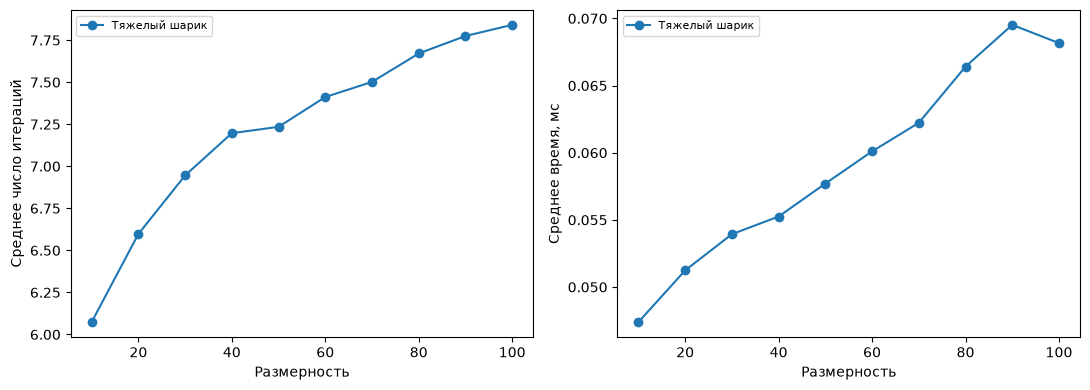

In [14]:
def summarize_by_n(runs):
    return runs.groupby(["n", "method"], sort=False).agg(
        iterations=("iterations", "mean"), time_ms=("time_ms", "mean")
    )

def plot_by_n(summary):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, column, ylabel in zip(axes, ("iterations", "time_ms"),
                                  ("Среднее число итераций", "Среднее время, мс")):
        for method, data in summary.groupby(level="method", sort=False):
            series = data.droplevel("method")[column]
            ax.plot(series.index, series, "o-", label=method)
        ax.set(xlabel="Размерность", ylabel=ylabel)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

strong_problems = results.loc[strong_indices]
mean_sqrt_kappa = np.sqrt(strong_problems["kappa"]).groupby(strong_problems["n"]).mean()
fixed_by_n = summarize_by_n(strong_runs).join(mean_sqrt_kappa.rename("mean_sqrt_kappa"), on="n")
display(fixed_by_n.round(3))
plot_by_n(fixed_by_n)

При увеличении $n$ от 10 до 100 среднее значение $\sqrt{L/\mu}$ в последнем столбце выросло с $2.362$ до $2.541$, а среднее число итераций выросло с $6.074$ до $7.841$. Такая общая тенденция согласуется с теоретической оценкой.

### 4c. Точность в зависимости от числа итераций

Возьмём первую задачу при $n=10$ и $\alpha=1$ и запустим метод из первых трёх начальных точек этой задачи.

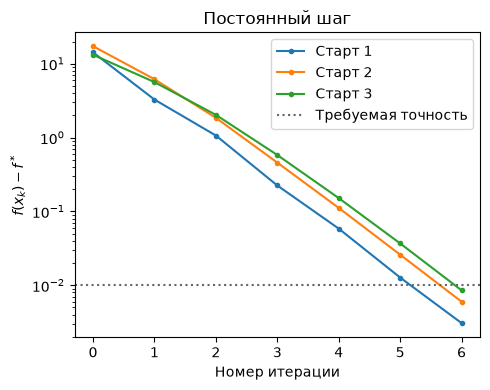

,Шаг,Старт,Итерации,Конечная ошибка,Точность достигнута,Проверки при подборе шага
0,Постоянный шаг,1,6,0.003072,True,0
1,Постоянный шаг,2,6,0.005990,True,0
2,Постоянный шаг,3,6,0.008535,True,0


In [15]:
example_index = results.index[(results["n"] == 10) & (results["alpha"] == 1)][0]
example = problems[example_index]
example_data = results.loc[example_index]
starts = initial_points[example_index][:3]

def example_runs(solver):
    return [solver(example, x0, example_data["f_star"], example_data["L"], example_data["mu"],
                   eps=accuracy, keep_history=True) for x0 in starts]

def plot_accuracy(samples):
    fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 4),
                             sharex=True, sharey=True, squeeze=False)
    rows = []
    for ax, (label, runs) in zip(axes[0], samples.items()):
        for number, run in enumerate(runs, start=1):
            ax.semilogy(run.errors, "o-", markersize=3, label=f"Старт {number}")
            rows.append({
                "Шаг": label, "Старт": number, "Итерации": run.iterations,
                "Конечная ошибка": run.errors[-1], "Точность достигнута": run.converged,
                "Проверки при подборе шага": run.total_checks
            })
        ax.axhline(accuracy, color="0.4", linestyle=":", label="Требуемая точность")
        ax.set(title=label, xlabel="Номер итерации")
        ax.legend()
    axes[0, 0].set_ylabel("$f(x_k)-f^*$")
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame(rows))

samples = {"Постоянный шаг": example_runs(run_heavy_ball)}
plot_accuracy(samples)

На выбранной задаче при $n=10$ метод с постоянным шагом достиг требуемой точности за 6 итераций из каждой из трёх показанных начальных точек.

### 4d. Адаптивный подбор шага для метода тяжелого шарика

Обозначим через $M$ пробную оценку $L$. Для первого подбора берем $M=L/2$, для следующих делим предыдущую принятую оценку пополам. Снизу ограничиваем $M$ величиной $\mu$ и малой положительной величиной $L\varepsilon_{\rm mach}$.

Сначала вычисляем шаг тяжелого шарика с параметрами для $M$. Принимаем пробную точку $z$, если

$$f(z)\le f(x_k)-\frac{\|\nabla f(x_k)\|_2^2}{2M}.$$

Если шаг с инерцией не дал достаточного уменьшения, в качестве запасного варианта проверяем градиентный шаг $z=x_k-\nabla f(x_k)/M$. При повторном отказе удваиваем $M$ и повторяем обе проверки. Из липшицевости градиента следует, что при $M\ge L$ градиентный шаг удовлетворяет условию. Число проверок считаем по всем пробным точкам, включая принятую.

In [16]:
def adaptive_heavy_ball_step(problem, x, value, grad, displacement, M, L, mu, parameters):
    M = max(M / 2, mu, L * np.finfo(float).eps)
    grad_squared = grad @ grad
    checks = 0
    trial_L_sum = 0.0
    for rounds in range(1, 65):
        step, beta = parameters(M, mu)
        threshold = value - grad_squared / (2 * M)
        for direction in (-step * grad + beta * displacement, -grad / M):
            candidate = x + direction
            candidate_value = objective(problem, candidate)
            checks += 1
            trial_L_sum += M
            if candidate_value <= threshold:
                return candidate, candidate_value, M, checks, trial_L_sum, rounds
        M *= 2
    raise ArithmeticError("Не удалось подобрать шаг метода тяжелого шарика.")

def adaptive_heavy_ball(problem, x0, f_star, L, mu, eps=0.01, keep_history=False):
    return run_heavy_ball(problem, x0, f_star, L, mu, eps=eps, keep_history=keep_history,
                          choose_step=adaptive_heavy_ball_step)

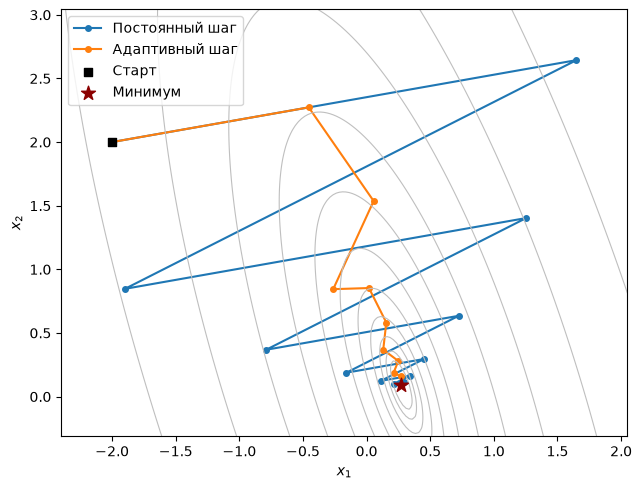

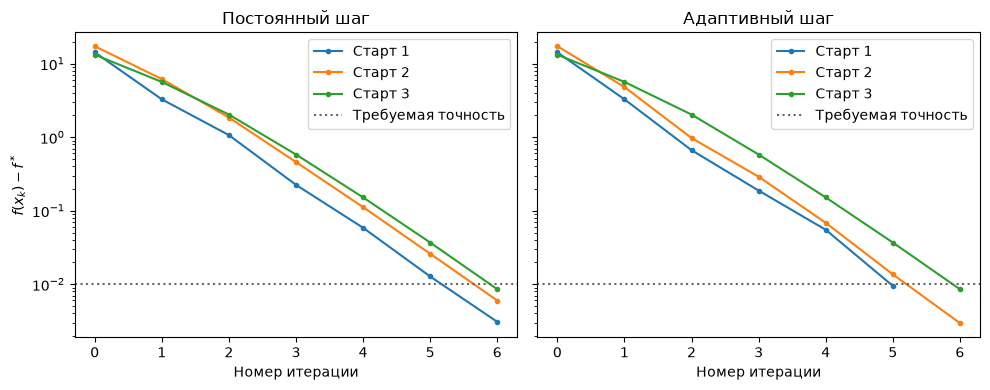

,Шаг,Старт,Итерации,Конечная ошибка,Точность достигнута,Проверки при подборе шага
0,Постоянный шаг,1,6,0.003072,True,0
1,Постоянный шаг,2,6,0.005990,True,0
2,Постоянный шаг,3,6,0.008535,True,0
3,Адаптивный шаг,1,5,0.009491,True,17
4,Адаптивный шаг,2,6,0.002953,True,17
5,Адаптивный шаг,3,6,0.008535,True,18


In [17]:
plane_adaptive = adaptive_heavy_ball(plane_problem, plane_start, plane_value, plane_L, plane_mu,
                                     keep_history=True)
paths["Адаптивный шаг"] = np.array(plane_adaptive.trajectory)
plot_trajectories(paths)

samples["Адаптивный шаг"] = example_runs(adaptive_heavy_ball)
plot_accuracy(samples)

При $n=2$ подбор шага сократил число итераций с 11 до 9. При $n=10$ он сэкономил одну итерацию на первом старте, а на двух остальных число итераций осталось прежним.

,Число пар
Меньше итераций с подбором,6558
Столько же итераций,38031
Больше итераций с подбором,5411


iterations                                time_ms  \
method Тяжелый шарик Тяжелый шарик с подбором Тяжелый шарик   
n                                                             
10             6.074                    5.639         0.047   
20             6.597                    6.357         0.051   
30             6.946                    6.849         0.054   
40             7.197                    7.135         0.055   
50             7.235                    7.224         0.058   
60             7.412                    7.470         0.060   
70             7.502                    7.613         0.062   
80             7.671                    7.768         0.066   
90             7.775                    7.878         0.070   
100            7.841                    7.947         0.068   

                                 
method Тяжелый шарик с подбором  
n                                
10                        0.115  
20                        0.133  
30                        0.139  
40                        0.144  
50                        0.151  
60                        0.159  
70                        0.163  
80                        0.170  
90                        0.177  
100                       0.182

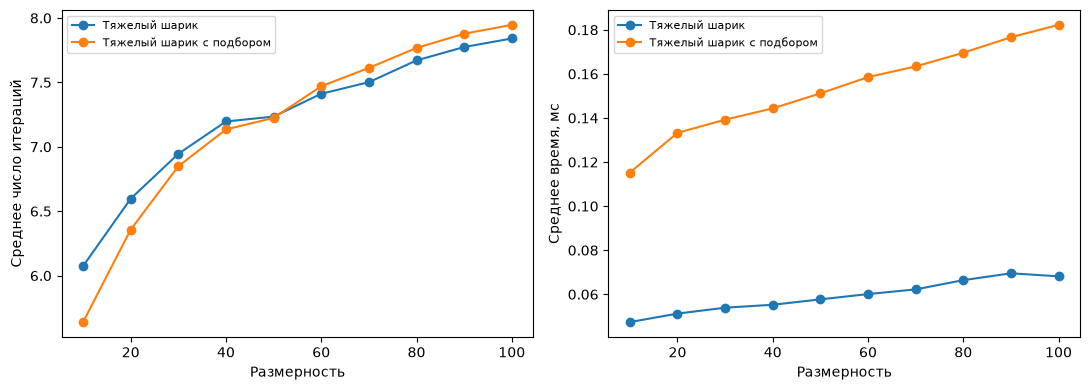

In [18]:
def compare_iterations(runs):
    paired_iterations = runs.pivot(index=["problem", "start"], columns="method", values="iterations")
    saved_iterations = paired_iterations[fixed_label] - paired_iterations[adaptive_label]
    return pd.Series({
        "Меньше итераций с подбором": (saved_iterations > 0).sum(),
        "Столько же итераций": (saved_iterations == 0).sum(),
        "Больше итераций с подбором": (saved_iterations < 0).sum(),
    }, name="Число пар").to_frame()

adaptive_label = "Тяжелый шарик с подбором"
strong_adaptive = benchmark(strong_indices, adaptive_label, adaptive_heavy_ball)
strong_both = pd.concat([strong_runs, strong_adaptive], ignore_index=True)
display(compare_iterations(strong_both))
strong_by_n = summarize_by_n(strong_both)
display(strong_by_n.unstack("method").round(3))
plot_by_n(strong_by_n)

### 4e. Зависимость скорости сходимости от $\mu/L$

Обозначим $r=\mu/L$ и $e_k=x_k-x^*$. Тогда

$$\nabla f(x_k)=He_k.$$

Симметричная матрица $H$ допускает разложение

$$H=QT Q^\top,\qquad Q^\top Q=I_n,\qquad
T=\operatorname{diag}(\lambda_1,\ldots,\lambda_n),\qquad
\mu\le\lambda_i\le L.$$

В координатах $z_k=Q^\top e_k$ каждое собственное направление развивается
независимо. Поэтому достаточно исследовать скалярную компоненту ошибки
$z_k$ для одного собственного значения $\lambda$.

### Метод тяжелого шарика

Итерация имеет вид
$$x_{k+1}=x_k-h\nabla f(x_k)+\beta(x_k-x_{k-1}),$$
где $h>0$ - шаг, $\beta$ - коэффициент моментума.
Возьмем следующие значения параметров:
$$
h=\frac4{(\sqrt L+\sqrt\mu)^2},\qquad
\beta=\left(\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}\right)^2.
$$
Вычтем $x^*$ из обеих частей:

$$x_{k+1}-x^*=x_k-x^*-h\nabla f(x_k)+\beta(x_k-x_{k-1}).$$

Пусть $e_k=x_k-x^*$. Тогда используя $\nabla f(x_k)=He_k$ имеем

$$e_{k+1}=e_k-hHe_k+\beta(e_k-e_{k-1}).$$

Раскрыв скобки и сгруппировав слагаемые с $e_k$, получаем

$$e_{k+1}=(I_n-hH+\beta I_n)e_k-\beta e_{k-1}.$$

Умножим это равенство на $Q^\top$ и перейдем к собственным координатам
$z_k=Q^\top e_k$. В этих координатах матрица $H$ действует на каждую
компоненту умножением на соответствующее собственное значение $\lambda$.
Для одной такой компоненты получаем

$$z_{k+1}=(1-h\lambda+\beta)z_k-\beta z_{k-1}.$$

Подстановка решения вида $z_k=t^k$ дает характеристическое уравнение
$$t^2-(1-h\lambda+\beta)t+\beta=0.$$

Положим
$$\rho=\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}.$$
При $\mu<L$ имеем $0<\rho<1$ и $\beta=\rho^2$.
Так как коэффициент $c(\lambda)=1-h\lambda+\beta$ линейно убывает по $\lambda$ и $\lambda\in[\mu,L]$:
$$c(\mu)=2\rho,\qquad c(L)=-2\rho.$$
Значит, $|c(\lambda)|\le2\rho$ и дискриминант характеристического уравнения
$c(\lambda)^2-4\rho^2\le0$.
При отрицательном дискриминанте корни комплексно сопряжены,
а их произведение равно $\rho^2$, поэтому модуль каждого равен $\rho$.
При нулевом дискриминанте получаются кратные корни $\rho$ или $-\rho$.

Получаем
$$
\rho_{\rm HB}
=\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}
=\frac{1-\sqrt r}{1+\sqrt r}.
$$

### Метод Нестерова

Сначала будет произведена экстраполяция, затем градиентный шаг
в экстраполированной точке. Шаг равен $h=1/L$:
$$
y_k=x_k+\beta(x_k-x_{k-1}),\qquad
x_{k+1}=y_k-\frac1L\nabla f(y_k),
$$
$$\beta=\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}.$$
Как и раньше, обозначим ошибку $e_k=x_k-x^*$. Для нашей квадратичной
функции из $\nabla f(x^*)=0$ следует

$$\nabla f(y_k)=H(y_k-x^*).$$

Из формулы экстраполяции имеем

$$y_k-x^*=e_k+\beta(e_k-e_{k-1}).$$

Раскроем скобки

$$y_k-x^*=(1+\beta)e_k-\beta e_{k-1}.$$

Вычтем $x^*$ из градиентного шага и подставим выражение для градиента:

$$e_{k+1}=(y_k-x^*)-\frac1LH(y_k-x^*).$$

Выносим общий множитель:

$$e_{k+1}=\left(I_n-\frac HL\right)(y_k-x^*).$$

Подставим выражение для $y_k-x^*$

$$\boxed{e_{k+1}=\left(I_n-\frac HL\right)
\bigl((1+\beta)e_k-\beta e_{k-1}\bigr)}.$$

Перейдем к собственным координатам $z_k=Q^\top e_k$. В одном собственном
направлении матрица $H$ действует как умножение на собственное значение
$\lambda$. Поэтому для соответствующей компоненты ошибки

$$\boxed{z_{k+1}=\left(1-\frac\lambda L\right)
\bigl((1+\beta)z_k-\beta z_{k-1}\bigr)}.$$

Пусть

$$s=\sqrt{\frac\mu L}\in(0,1),\qquad u=1-\frac\lambda L.$$

Поскольку $\mu\le\lambda\le L$, деление на $L>0$ дает

$$\frac\mu L\le\frac\lambda L\le1.$$

Вычтем из единицы

$$0\le1-\frac\lambda L\le1-\frac\mu L.$$

Так как $\mu/L=s^2$, это означает

$$\boxed{0\le u\le1-s^2}.$$

Кроме того, разделив числитель и знаменатель в формуле для $\beta$
на $\sqrt L$, получаем

$$\beta=\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}
=\frac{1-\sqrt{\mu/L}}{1+\sqrt{\mu/L}}
\quad\Longrightarrow\quad\boxed{\beta=\frac{1-s}{1+s}}.$$

С этими обозначениями рекуррентное соотношение принимает вид

$$z_{k+1}=u\bigl((1+\beta)z_k-\beta z_{k-1}\bigr).$$

Подстановка решения вида $z_k=t^k$ дает характеристическое уравнение:
$$t^2-u(1+\beta)t+u\beta=0.$$
Его дискриминант равен
$$
D=u\bigl(u(1+\beta)^2-4\beta\bigr)\le0,
$$
поскольку
$$u\le1-s^2=\frac{4\beta}{(1+\beta)^2}.$$
Модуль корней   равен
$$|t|=\sqrt{u\beta}\le\sqrt{(1-s^2)\frac{1-s}{1+s}}=1-s.$$
На границе $\lambda=\mu$ получаем кратный корень $1-s$,
поэтому максимум по спектру достигается и
$$\rho_{\rm N}=1-\sqrt{\mu/L}=1-\sqrt r.$$

Заметим, что при $\mu=L$ получаем $H=LI_n$, $\beta=0$ и
$e_{k+1}=(I_n-H/L)e_k=0$, то есть достаточно одного шага.
Это также верно и для Heavy Ball, его параметры в этом случае будут
$h=1/L,\beta=0$.

Скорость сходимости зависит от $\mu/L$.

Видно, что при $0<\mu<L$ увеличение $\mu/L$
уменьшает $\rho$. Поэтому при выбранных параметрах
методов большее $\mu/L$ означает более быструю сходимость в худшем случае.
Когда $\mu/L$ приближается к нулю, сходимость замедляется.

### 4f. Принятые оценки $L$, итерации внутреннего цикла и проверки функции

На каждой итерации внутреннего цикла подбора шага выбираем одно значение $M$. С ним проверяем шаг тяжелого шарика и при необходимости градиентный шаг. После принятия точки завершается одна внешняя итерация.

Для каждой траектории с хотя бы одним шагом вычислим два средних. Для первого учитываем $M$ один раз на принятую итерацию. Для второго учитываем $M$ при каждом вычислении функции в пробной точке, включая отклоненные пробы. Каждое среднее делим на глобальное $L$ той же задачи, затем усредняем отношения по траекториям. Для оценки затрат разделим число итераций внутреннего цикла и число проверок функции на число внешних итераций группы.

In [19]:
def summarize_steps(runs):
    adaptive_runs = runs[runs["iterations"] > 0].copy()
    adaptive_runs["accepted_L"] = adaptive_runs["accepted_L_sum"] / adaptive_runs["iterations"]
    adaptive_runs["trial_L"] = adaptive_runs["trial_L_sum"] / adaptive_runs["checks"]
    adaptive_runs["accepted_ratio"] = adaptive_runs["accepted_L"] / adaptive_runs["L"]
    adaptive_runs["trial_ratio"] = adaptive_runs["trial_L"] / adaptive_runs["L"]

    step_summary = adaptive_runs.groupby("mu").agg(
        global_L=("L", "mean"), accepted_L=("accepted_L", "mean"), trial_L=("trial_L", "mean"),
        accepted_ratio=("accepted_ratio", "mean"), trial_ratio=("trial_ratio", "mean"),
        rounds=("rounds", "sum"), checks=("checks", "sum"), iterations=("iterations", "sum")
    )
    step_summary["rounds_per_iteration"] = step_summary["rounds"] / step_summary["iterations"]
    step_summary["checks_per_iteration"] = step_summary["checks"] / step_summary["iterations"]
    return step_summary[["global_L", "accepted_L", "trial_L", "accepted_ratio", "trial_ratio",
                         "rounds_per_iteration", "checks_per_iteration"]]

step_labels = {
    "rounds_per_iteration": "Итераций внутреннего цикла на внешний шаг",
    "checks_per_iteration": "Проверок функции на внешний шаг",
}
summarize_steps(strong_adaptive).rename(columns=step_labels).round(3)

,global_L,accepted_L,trial_L,accepted_ratio,trial_ratio,Итераций внутреннего цикла на внешний шаг,Проверок функции на внешний шаг
mu,,,,,,,
1.0,6.258,5.893,3.971,0.942,0.635,1.993,3.064


При $\mu=1$ среднее отношение принятой оценки к $L$ равно 0.942, а по всем проверкам 0.635. На одну внешнюю итерацию пришлось в среднем 1.99 итерации внутреннего цикла и 3.06 проверки функции.

### 4g. Случай $\mu=0$

При $\mu=0$ прямая подстановка в параметры Поляка дает $h=4/L$ и $\beta=1$. Для собственного направления с $\lambda=L$ характеристический многочлен равен $(t+1)^2$. Ошибка в этом направлении может расти. Поэтому для случая $\mu=0$ выберем шаг $h=1/L$ и будем сохранять половину предыдущего перемещения, то есть положим $\beta=1/2$.

Проверим этот выбор. Для каждого положительного собственного значения гессиана имеем $0<h\lambda\le1$. Характеристический многочлен равен $t^2-(1+\beta-h\lambda)t+\beta$. Комплексно сопряженные корни имеют модуль $\sqrt\beta<1$. Если корни вещественные, они положительны, их произведение равно $\beta<1$, а значение многочлена при $t=1$ равно $h\lambda>0$. Поэтому оба корня меньше единицы. В ядре гессиана начальная скорость равна нулю, и соответствующая компонента точки сохраняется.

Ошибка по функции стремится к нулю по мере затухания компонент в положительной части спектра. При постоянном шаге на отдельных итерациях ошибка может возрастать. Отдельно сравним оба варианта тяжелого шарика на задачах с $\mu=0$ и $\mu=1$.

In [20]:
def heavy_ball_parameters(L, mu):
    if mu == 0:
        return 1 / L, 0.5
    return polyak_parameters(L, mu)


def heavy_ball(problem, x0, f_star, L, mu, eps=0.01, adaptive=False,
               keep_history=False, max_iter=10000):
    return run_heavy_ball(
        problem, x0, f_star, L, mu, eps=eps, keep_history=keep_history, max_iter=max_iter,
        parameters=heavy_ball_parameters,
        choose_step=adaptive_heavy_ball_step if adaptive else None
    )

In [21]:
from functools import partial

flat_indices = results.index[results["mu"] == 0]
flat_fixed = benchmark(flat_indices, fixed_label, heavy_ball)
flat_adaptive = benchmark(flat_indices, adaptive_label, partial(heavy_ball, adaptive=True))
hb_runs = pd.concat([strong_both, flat_fixed, flat_adaptive], ignore_index=True)
print(f"Выполнено запусков: {len(hb_runs)}")
print(f"Требуемая точность достигнута: {hb_runs['converged'].sum()}")

Выполнено запусков: 200000
Требуемая точность достигнута: 200000


Объединим обе группы задач для итоговых таблиц по размерностям, стоимости подбора шага и $\mu$:

iterations                                time_ms  \
method Тяжелый шарик Тяжелый шарик с подбором Тяжелый шарик   
n                                                             
10            10.005                    6.066         0.074   
20            13.366                    7.882         0.100   
30            12.024                    8.252         0.092   
40            13.231                    8.792         0.101   
50            14.813                    9.389         0.118   
60            15.881                    9.819         0.124   
70            16.256                   10.024         0.134   
80            16.911                   10.296         0.137   
90            16.757                   10.374         0.144   
100           17.962                   10.716         0.156   

                                 
method Тяжелый шарик с подбором  
n                                
10                        0.113  
20                        0.152  
30                        0.158  
40                        0.170  
50                        0.183  
60                        0.195  
70                        0.203  
80                        0.208  
90                        0.218  
100                       0.227

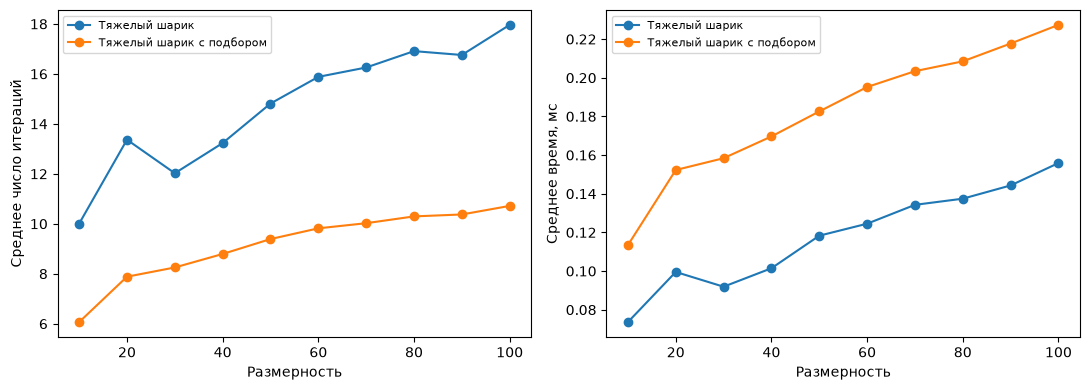

,Число пар
Меньше итераций с подбором,56505
Столько же итераций,38065
Больше итераций с подбором,5430


,global_L,accepted_L,trial_L,accepted_ratio,trial_ratio,Итераций внутреннего цикла на внешний шаг,Проверок функции на внешний шаг
mu,,,,,,,
0.0,5.265,2.786,2.023,0.531,0.386,1.887,2.991
1.0,6.258,5.893,3.971,0.942,0.635,1.993,3.064


In [22]:
hb_by_n = summarize_by_n(hb_runs)
display(hb_by_n.unstack("method").round(3))
plot_by_n(hb_by_n)
display(compare_iterations(hb_runs))

step_summary = summarize_steps(hb_runs[hb_runs["method"] == adaptive_label])
display(step_summary.rename(columns=step_labels).round(3))

In [23]:
hb_by_mu = hb_runs.groupby(["mu", "method"], sort=False).agg(
    runs=("converged", "size"), converged=("converged", "sum"),
    iterations=("iterations", "mean"), time_ms=("time_ms", "mean")
)
hb_by_mu.round(3)

runs  converged  iterations  time_ms
mu  method                                                         
1.0 Тяжелый шарик             50000      50000       7.225    0.059
    Тяжелый шарик с подбором  50000      50000       7.188    0.153
0.0 Тяжелый шарик             50000      50000      22.216    0.177
    Тяжелый шарик с подбором  50000      50000      11.134    0.212

При $\mu=0$ подбор шага сократил среднее число итераций с 22,22 до 11,13. При $\mu=1$ разница мала: 7,22 итерации с постоянным шагом и 7,19 с адаптивным. По среднему времени в этом эксперименте в обеих группах быстрее оказался метод с постоянным шагом.